# Stage 4 (Week 3): Extended 5-Fold Out-of-Fold Logistic Auditing & Head-to-Head Defense Comparison

**Objective:** Compare the primary geometry-based **$k$-NN neighborhood-disagreement defense** ($k=10, \tau=0.5$) against the extended model-based **5-fold out-of-fold (`StratifiedKFold`) standardized logistic-regression defense** ($\tau_{\text{OOF}}=0.8$) under identical $10\%$ poisoning conditions across both attacks (`random`, `targeted`), all three classifiers (`Logistic Regression`, `Decision Tree`, `Random Forest`), and all 10 seeds ($0$–$9$).

## 1. Dataset & Protocol Alignment Check at 10% Poisoning
We load the saved $10\%$ poisoning runs from `results/knn_defense_results.csv` ($60$ rows) and `results/oof_defense_results.csv` ($60$ rows) and confirm that both defenses share identical data splits, poison counts ($N_{\text{poison}} = 368$), and baseline metrics.

In [1]:
# Cell 1: Load saved k-NN and 5-fold OOF defense results at 10% poisoning
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

knn_df = pd.read_csv('../results/knn_defense_results.csv')
oof_df = pd.read_csv('../results/oof_defense_results.csv')
knn_10_df = knn_df[np.isclose(knn_df['poison_rate'], 0.10)].copy()
combined_10_df = pd.concat([knn_10_df, oof_df], ignore_index=True)

assert len(knn_10_df) == 60 and len(oof_df) == 60
print('=== STAGE 4 WEEK 3: TWO-DEFENSE HEAD-TO-HEAD DATASET VERIFICATION (10% POISONING) ===')
print(f'k-NN 10% rows loaded:         {len(knn_10_df)} (Expected: 60 = 10 seeds x 2 attacks x 3 models)')
print(f'5-Fold OOF 10% rows loaded:   {len(oof_df)} (Expected: 60 = 10 seeds x 2 attacks x 3 models)')
print(f'Combined comparison rows:     {len(combined_10_df)} (Expected: 120)')
print('✓ Verification Passed: Both defenses evaluated on identical 10% poisoning splits and poisoned samples.')

=== STAGE 4 WEEK 3: TWO-DEFENSE HEAD-TO-HEAD DATASET VERIFICATION (10% POISONING) ===
k-NN 10% rows loaded:         60 (Expected: 60 = 10 seeds x 2 attacks x 3 models)
5-Fold OOF 10% rows loaded:   60 (Expected: 60 = 10 seeds x 2 attacks x 3 models)
Combined comparison rows:     120 (Expected: 120)
✓ Verification Passed: Both defenses evaluated on identical 10% poisoning splits and poisoned samples.


## 2. Detection Benefit, False-Removal Cost, and Runtime Comparison (10% Poisoning)
We compare `detection_precision`, `detection_recall`, `detection_f1`, total `n_flagged`, clean samples incorrectly removed (`n_clean_removed`, `frac_clean_removed`), and `audit_runtime_sec` across all 10 seeds (`Table 1` and `Figure 9`).

=== TABLE 1: TWO-DEFENSE AUDITING QUALITY, CLEAN REMOVAL COST & RUNTIME AT 10% POISONING (SEEDS 0–9) ===
  attack                   defense  n_poisoned      Flagged         Clean Removed Detection Precision Detection Recall    Detection F1 Audit Runtime (s)
  random        k-NN (k=10, τ=0.5)         368 773.4 ± 18.3 434.7 ± 17.3 (13.12%)     0.4381 ± 0.0102  0.9204 ± 0.0136 0.5936 ± 0.0106   0.0549 ± 0.0005
  random 5-Fold OOF LogReg (τ=0.8)         368  216.4 ± 8.7    36.6 ± 3.9 (1.11%)     0.8309 ± 0.0168  0.4886 ± 0.0217 0.6151 ± 0.0196   0.0562 ± 0.0043
targeted        k-NN (k=10, τ=0.5)         368 763.4 ± 24.5 484.0 ± 18.5 (14.61%)     0.3661 ± 0.0100  0.7592 ± 0.0287 0.4939 ± 0.0135   0.0545 ± 0.0005
targeted 5-Fold OOF LogReg (τ=0.8)         368  124.2 ± 6.7    53.0 ± 4.0 (1.60%)     0.5729 ± 0.0290  0.1935 ± 0.0162 0.2891 ± 0.0213   0.0970 ± 0.0030


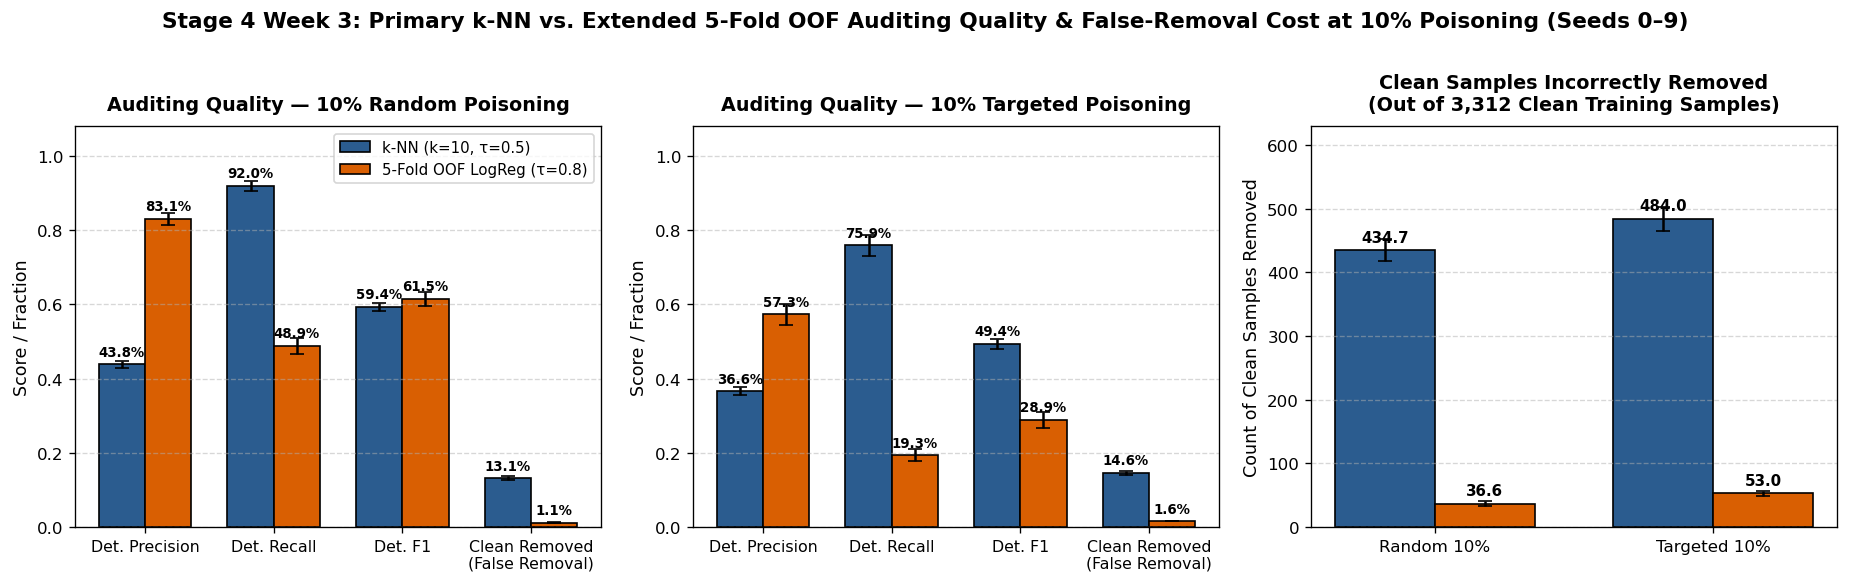

In [2]:
# Cell 2: Two-Defense Detection & Cost Summary Table and Figure 9
comp_det_df = pd.read_csv('../results/tables/two_defense_detection_10pct.csv')
det_cols = ['attack', 'defense', 'n_poisoned', 'Flagged', 'Clean Removed', 'Detection Precision', 'Detection Recall', 'Detection F1', 'Audit Runtime (s)']
print('=== TABLE 1: TWO-DEFENSE AUDITING QUALITY, CLEAN REMOVAL COST & RUNTIME AT 10% POISONING (SEEDS 0–9) ===')
print(comp_det_df[det_cols].to_string(index=False))

img9 = plt.imread('../results/figures/fig9_two_defense_detection_and_cost_10pct.png')
plt.figure(figsize=(15.5, 4.8))
plt.imshow(img9)
plt.axis('off')
plt.show()

## 3. Downstream Spam Recall and Spam F1 Recovery Comparison at 10% Poisoning
Next, we evaluate how effectively each defense recovers lost `spam_recall` and `spam_f1` across all three model families (`Table 2` and `Figure 10`), retaining and explaining negative recovery values.

=== TABLE 2: TWO-DEFENSE DOWNSTREAM PERFORMANCE RECOVERY AT 10% POISONING (SEEDS 0–9) ===
  attack               model                   defense Clean Recall Poisoned Recall Defended Recall Recall Recovery (Mean) Recall Recovery (Seed Mean±Std) Clean F1 Poisoned F1     Defended F1 F1 Recovery (Mean) Total Runtime (s)
  random Logistic Regression        k-NN (k=10, τ=0.5)       0.8848          0.8303 0.8702 ± 0.0176                  73.2%                   76.1% ± 15.0%   0.9014      0.8702 0.8907 ± 0.0102              65.6%   0.0695 ± 0.0015
  random Logistic Regression 5-Fold OOF LogReg (τ=0.8)       0.8848          0.8303 0.8934 ± 0.0185                 115.7%                  123.8% ± 27.6%   0.9014      0.8702 0.9023 ± 0.0105             102.7%   0.0748 ± 0.0046
  random       Decision Tree        k-NN (k=10, τ=0.5)       0.8708          0.8468 0.8314 ± 0.0290                 -64.4%                -120.5% ± 185.9%   0.8899      0.8740 0.8701 ± 0.0173             -24.2%   0.0707 ± 0

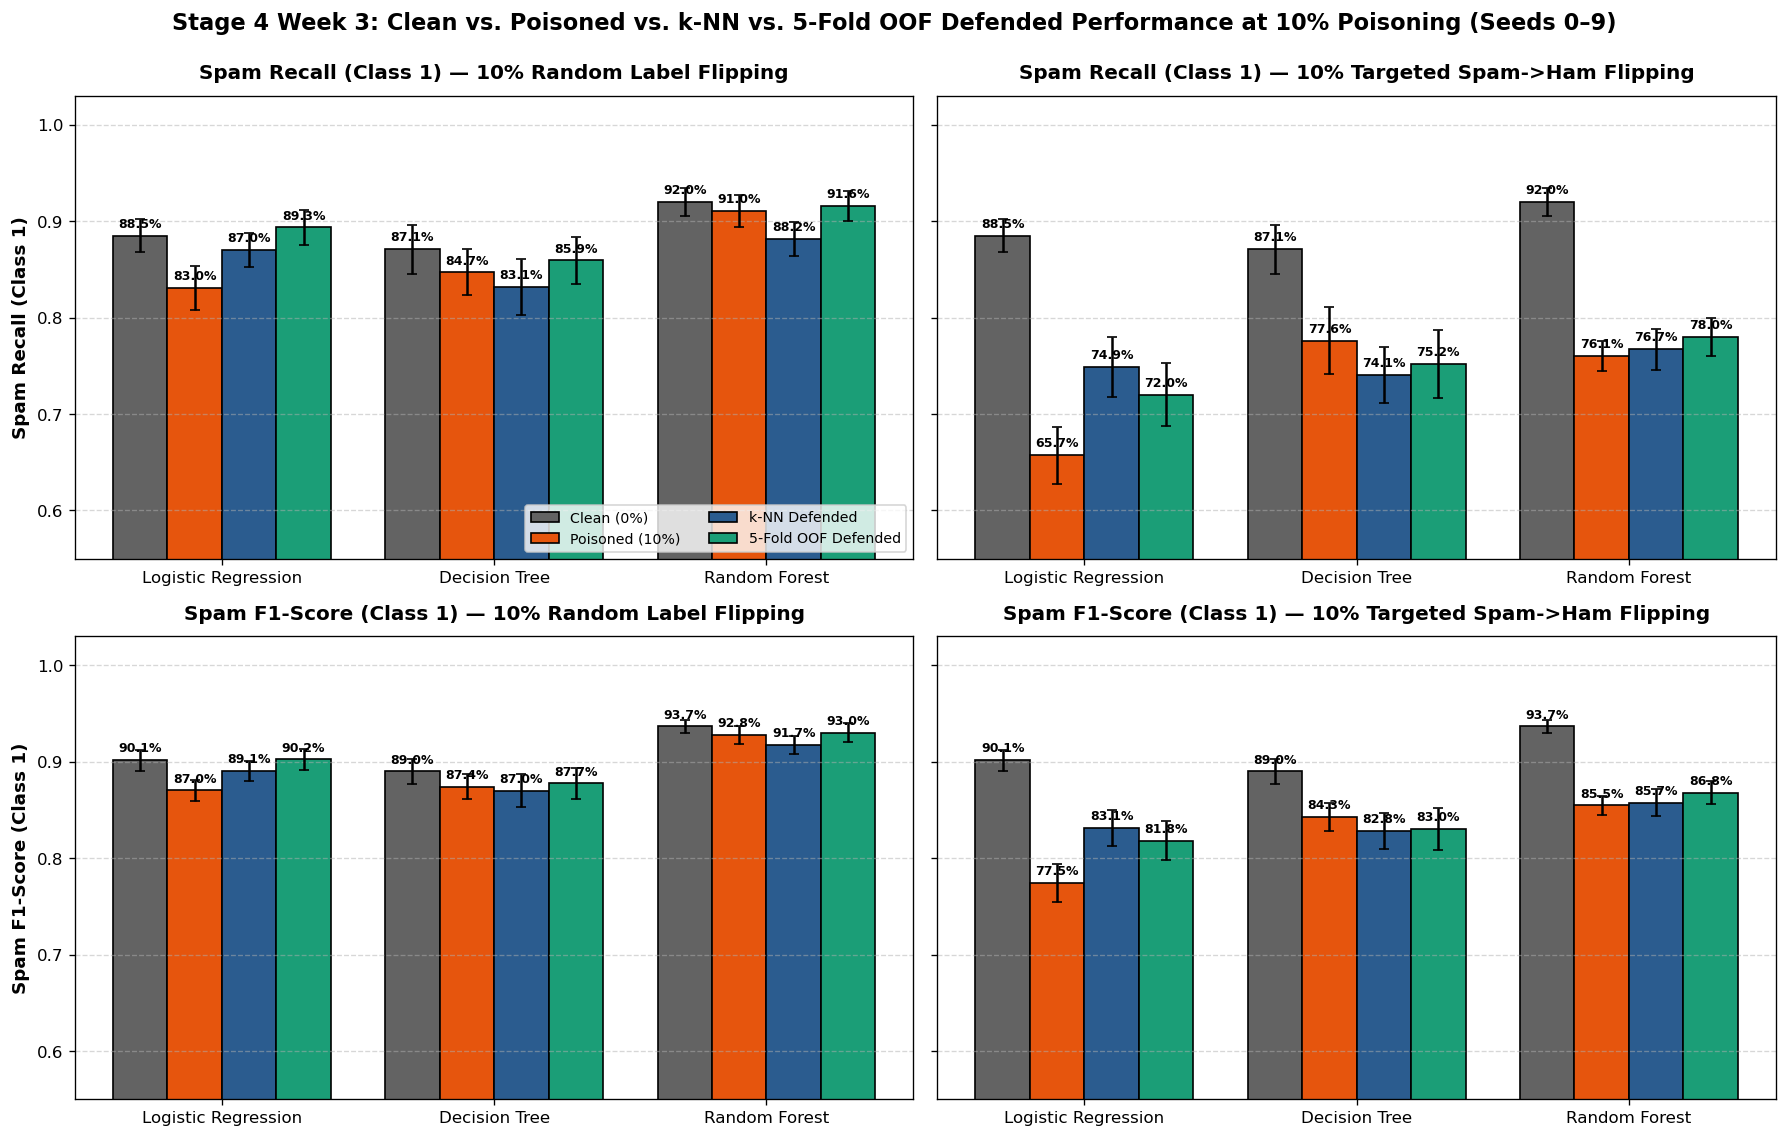

In [3]:
# Cell 3: Two-Defense Downstream Recovery Table and Figure 10
comp_model_df = pd.read_csv('../results/tables/two_defense_comparison_10pct.csv')
m_cols = ['attack', 'model', 'defense', 'Clean Recall', 'Poisoned Recall', 'Defended Recall', 'Recall Recovery (Mean)', 'Recall Recovery (Seed Mean±Std)', 'Clean F1', 'Poisoned F1', 'Defended F1', 'F1 Recovery (Mean)', 'Total Runtime (s)']
print('=== TABLE 2: TWO-DEFENSE DOWNSTREAM PERFORMANCE RECOVERY AT 10% POISONING (SEEDS 0–9) ===')
print(comp_model_df[m_cols].to_string(index=False))

img10 = plt.imread('../results/figures/fig10_two_defense_recovery_10pct.png')
plt.figure(figsize=(15, 9.5))
plt.imshow(img10)
plt.axis('off')
plt.show()

## 4. Detailed Seed 0 Error Analysis: False Positives, Missed Poisons, and Test-Set Error Recovery
We inspect concrete training and test examples on `Seed 0` to trace how both defenses behave on individual emails, and we also inspect the Seed 0 test-set vote probabilities at $20\%$ targeted poisoning to contextualize our tentative interpretation of the Decision Tree vs. Random Forest crossover.

In [4]:
# Cell 4: Seed 0 Qualitative Inspection of False Positives, Missed Poisoned Samples, and Test-Set Errors
from src.data import load_spambase, split_data
from src.attacks import targeted_spam_to_ham
from src.models import get_models
from src.defense import knn_label_audit, oof_logreg_label_audit

df_full = load_spambase('../data/spambase.data', '../data/spambase.names')
X_train0, X_test0, y_train0, y_test0 = split_data(df_full, test_size=0.2, random_state=0)
y_targ10, mask_targ10 = targeted_spam_to_ham(y_train0, poison_rate=0.10, random_state=0)

knn_audit0 = knn_label_audit(X_train0, y_targ10, k=10, threshold=0.5)
oof_audit0 = oof_logreg_label_audit(X_train0, y_targ10, n_splits=5, threshold=0.8, random_state=0)

key_feats = ['word_freq_remove', 'word_freq_free', 'word_freq_your', 'char_freq_!', 'char_freq_$', 'capital_run_length_average']
train_inspect_df = X_train0[key_feats].copy()
train_inspect_df['clean_label'] = y_train0.values
train_inspect_df['recorded_label'] = y_targ10.values
train_inspect_df['is_poisoned'] = mask_targ10
train_inspect_df['knn_score'] = np.round(knn_audit0['suspicion_scores'], 3)
train_inspect_df['knn_flagged'] = knn_audit0['flagged_mask']
train_inspect_df['oof_score'] = np.round(oof_audit0['suspicion_scores'], 3)
train_inspect_df['oof_flagged'] = oof_audit0['flagged_mask']

s0_err_df = pd.read_csv('../results/tables/seed0_test_error_summary.csv')
recovered_test_10 = pd.read_csv('../results/tables/seed0_test_error_recovery_examples.csv', index_col=0)

print('=== SEED 0 DETAILED ERROR ANALYSIS (10% TARGETED POISONING) ===')
print('A1. Representative False Positives Flagged by k-NN (Clean Training Samples Incorrectly Removed, Score >= 0.5):')
print(train_inspect_df[(~train_inspect_df['is_poisoned']) & train_inspect_df['knn_flagged']].head(5).to_string())
print('\nA2. Representative False Positives Flagged by 5-Fold OOF (Clean Training Samples Incorrectly Removed, Score >= 0.8):')
print(train_inspect_df[(~train_inspect_df['is_poisoned']) & train_inspect_df['oof_flagged']].head(5).to_string())
print('\nB1. Representative Missed Poisoned Samples by k-NN (Poisoned Spam Not Flagged, Score < 0.5):')
print(train_inspect_df[train_inspect_df['is_poisoned'] & (~train_inspect_df['knn_flagged'])].head(5).to_string())
print('\nB2. Representative Missed Poisoned Samples by 5-Fold OOF (Poisoned Spam Not Flagged, Score < 0.8):')
print(train_inspect_df[train_inspect_df['is_poisoned'] & (~train_inspect_df['oof_flagged'])].head(5).to_string())
print('\nC1. Seed 0 Test-Set Error Counts (FP / FN) Before Poisoning (0%), After Poisoning (10%), After k-NN, and After 5-Fold OOF:')
print(s0_err_df.to_string(index=False))
print('\nC2. Ten Representative Test-Set Spam Emails (True Label = 1) Across Clean (0%), 10% Targeted Poisoned, k-NN Defended, and OOF Defended Models:')
print(recovered_test_10.to_string())

y_targ20, _ = targeted_spam_to_ham(y_train0, poison_rate=0.20, random_state=0)
rf_20 = get_models(random_state=0)['Random Forest'].fit(X_train0, y_targ20)
dt_20 = get_models(random_state=0)['Decision Tree'].fit(X_train0, y_targ20)
spam_test_mask = (y_test0.values == 1)
rf_spam_probs_20 = rf_20.predict_proba(X_test0[spam_test_mask])[:, 1]
dt_spam_preds_20 = dt_20.predict(X_test0[spam_test_mask])
rf_spam_preds_20 = rf_20.predict(X_test0[spam_test_mask])
rf_in_twilight = int(((rf_spam_probs_20 >= 0.35) & (rf_spam_probs_20 < 0.50)).sum())
dt_caught_in_rf_twilight = int(((rf_spam_probs_20 >= 0.35) & (rf_spam_probs_20 < 0.50) & (dt_spam_preds_20 == 1)).sum())
print('\nD. Seed 0 Diagnostic Check on the 20% Targeted Poisoning DT vs. RF Crossover (N_spam_test = 363):')
print(f'  - Random Forest (200 trees) test-set spam recall: {rf_spam_preds_20.mean()*100:.2f}% ({int(rf_spam_preds_20.sum())}/363)')
print(f'  - Decision Tree (depth 8) test-set spam recall:   {dt_spam_preds_20.mean()*100:.2f}% ({int(dt_spam_preds_20.sum())}/363)')
print(f'  - Test spam instances where RF vote probability falls in twilight zone [0.35, 0.50): {rf_in_twilight}/363')
print(f'  - Of those {rf_in_twilight} twilight-zone spam emails missed by RF, Decision Tree classifies {dt_caught_in_rf_twilight} as Spam (1).')

=== SEED 0 DETAILED ERROR ANALYSIS (10% TARGETED POISONING) ===
A1. Representative False Positives Flagged by k-NN (Clean Training Samples Incorrectly Removed, Score >= 0.5):
      word_freq_remove  word_freq_free  word_freq_your  char_freq_!  char_freq_$  capital_run_length_average  clean_label  recorded_label  is_poisoned  knn_score  knn_flagged  oof_score  oof_flagged
3024              0.00            0.00            2.24        0.000        0.000                       2.000            0               0        False        0.5         True      0.101        False
105               0.00            0.64            0.00        0.662        0.000                      10.068            1               1        False        0.5         True      0.633        False
410               0.25            0.25            0.42        0.394        0.114                       7.484            1               1        False        0.5         True      0.360        False
1762              0.00       

## 5. Synthesis of Two-Defense Comparison, Negative Recovery Cases, and Limitations

### 1. Complementary Trade-offs Between Local Geometry ($k$-NN) and Global Margin (5-Fold OOF Logistic Regression) at 10% Poisoning
- **5-Fold OOF Logistic Auditing (`threshold = 0.8`) Minimizes False Removal and Excels Under Random Poisoning:**
  - Under **10% random poisoning**, 5-fold OOF achieves **$83.09\% \pm 1.68\%$ detection precision**, $48.86\% \pm 2.17\%$ detection recall, and **$61.51\% \pm 1.96\%$ detection F1** while removing only **$36.6 \pm 3.9$ clean training samples ($1.11\%$)**—nearly $12\times$ fewer false removals than $k$-NN ($434.7 \pm 17.3$ clean samples removed, $13.12\%$, detection precision $43.81\%$, detection F1 $59.36\%$). Both defenses execute in $\sim 0.055\text{–}0.056\text{ s}$ audit time (`Table 1`, `Figure 9`).
  - Because 5-fold OOF preserves $98.89\%$ of clean training data while pruning the most extreme random label flips, it **outperforms $k$-NN across all three classifiers under 10% random poisoning** (`Table 2`, `Figure 10`): restoring Logistic Regression recall from $83.03\% \to \mathbf{89.34\% \pm 1.85\%}$ (**$115.7\%$ recall recovery** [seed mean $123.8\% \pm 27.6\%$], **$102.7\%$ F1 recovery**), Decision Tree recall from $84.68\% \to \mathbf{85.92\% \pm 2.47\%}$ (**$51.7\%$ recall recovery**, **$21.7\%$ F1 recovery**), and Random Forest recall from $91.02\% \to \mathbf{91.57\% \pm 1.58\%}$ (**$57.1\%$ recall recovery**, **$24.3\%$ F1 recovery**).
- **$k$-NN Neighborhood Disagreement (`k = 10, threshold = 0.5`) Achieves Higher Detection Recall Under Targeted Evasion, Benefiting Linear Classifiers:**
  - Under **10% targeted spam-to-ham poisoning**, unidirectional corruption shifts the global logistic hyperplane toward the spam cluster, depressing out-of-fold predicted spam probabilities so that only $19.35\% \pm 1.62\%$ of poisoned spam samples exceed the strict $\tau_{\text{OOF}}=0.8$ threshold (`Detection Precision = 57.29%`, `Detection F1 = 28.91%`, clean removed $= 53.0 \pm 4.0$ [$1.60\%$], audit runtime $0.0970\text{ s}$). By contrast, local 10-NN neighborhood disagreement detects **$75.92\% \pm 2.87\%$** of targeted poisoned samples (`Detection Precision = 36.61%`, `Detection F1 = 49.39%`, audit runtime $0.0545\text{ s}$).
  - Consequently, for **Logistic Regression** under $10\%$ targeted poisoning, $k$-NN achieves substantially stronger recovery (**$40.2\%$ recall recovery** [$65.73\% \to 74.88\% \pm 3.11\%$] and **$44.6\%$ F1 recovery** [$77.47\% \to 83.13\% \pm 1.82\%$]) than 5-fold OOF (**$27.5\%$ recall recovery** [$65.73\% \to 71.98\% \pm 3.26\%$] and **$34.4\%$ F1 recovery** [$77.47\% \to 81.83\% \pm 2.06\%$]). Conversely, for **Random Forest**, 5-fold OOF's low false-removal cost ($1.60\%$ vs. $14.61\%$) yields higher recovery (**$11.9\%$ recall recovery** [$76.06\% \to 77.96\% \pm 1.96\%$] and **$16.0\%$ F1 recovery** [$85.47\% \to 86.78\% \pm 1.17\%$]) than $k$-NN ($4.2\%$ recall recovery and $3.3\%$ F1 recovery).

### 2. Explaining Negative Recovery Values Rather Than Discarding Them
- Under **10% random poisoning**, $k$-NN exhibits negative recovery for Decision Tree ($-64.4\%$ recall recovery) and Random Forest ($-297.1\%$ recall recovery, where the denominator $M_{\text{clean}} - M_{\text{poisoned}} = 0.9198 - 0.9102 = 0.0096$ is tiny, magnifying a $-2.87$ percentage-point drop from pruning $434.7$ clean boundary points). Under **10% targeted poisoning**, Decision Tree exhibits negative recovery under both $k$-NN ($-37.2\%$) and 5-fold OOF ($-25.6\%$) because single-tree splits rely on boundary spam examples that are pruned during filtering.

### 3. Epistemic Status of the DT vs. RF Crossover & Dataset Limitations
- On Seed 0 at $20\%$ targeted poisoning (`Cell 4C`), $120$ of the $363$ test spam emails receive Random Forest vote probabilities in the $[0.35, 0.50)$ twilight zone (just below the majority threshold), and the single Decision Tree classifies $65$ of those $120$ emails as spam. While this observation is consistent with our hypothesis of ensemble vote dilution versus isolated greedy splits, we continue to frame this explanation as an **interpretation** rather than a fully confirmed causal law across all feature-space partitions.
- Finally, because UCI Spambase is a historical 1999 corpus derived from a single Hewlett-Packard engineer's inbox containing personalized tokens (`word_freq_george`, `word_freq_hp`, `word_freq_650`), our findings establish controlled tabular benchmarking evidence rather than production security guarantees for modern neural or LLM-based spam filters.